In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
IMAGES = ROOT / "images"

load_dotenv(ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])

loans = pd.read_sql("SELECT * FROM loans WHERE bad IS NOT NULL", engine)
print(loans.shape)

(779026, 42)


### Out-of-time split
A random split would let the model see 2015 loans while being tested on other 2015 loans. A lender
never gets that luxury: it trains on the past and lends in the future. So the model trains on loans
issued **2007-2014** and is tested on loans issued **2015-2016**, which it never sees.

In [2]:
from features import CATEGORICAL, FEATURES, LC_PRICING, NUMERIC, add_features

X = add_features(loans)
y = loans["bad"].astype(int)

train = loans["issue_year"] <= 2014
test = loans["issue_year"] >= 2015
X_train, y_train = X[train], y[train]
X_test, y_test = X[test], y[test]

print(f"Training: {len(X_train):,} loans, default rate {y_train.mean():.1%}")
print(f"Test:     {len(X_test):,} loans, default rate {y_test.mean():.1%}")
print("Test terms:", loans.loc[test, "term"].value_counts().to_dict())

Training: 406,215 loans, default rate 15.2%
Test:     372,811 loans, default rate 15.2%
Test terms: {36: 372811}


In [3]:
from sklearn.metrics import brier_score_loss, roc_auc_score, roc_curve


def score(name, probs):
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    return {
        "model": name,
        "auc": round(auc, 4),
        "gini": round(2 * auc - 1, 4),
        "ks": round(np.max(tpr - fpr), 4),
        "brier": round(brier_score_loss(y_test, probs), 4),
        "avg_predicted_pd": round(probs.mean(), 4),
    }


results = []
test_probs = {}

### Baseline: Lending Club's own sub-grade
Lending Club already assigns every loan one of 35 sub-grades (A1 to G5). The baseline predicts each
loan's default probability as its sub-grade's default rate in the training years. Any model has to beat
this to be worth using.

In [4]:
subgrade_rates = y_train.groupby(loans.loc[train, "sub_grade"]).mean()
test_probs["Sub-grade baseline"] = loans.loc[test, "sub_grade"].map(subgrade_rates).fillna(y_train.mean()).to_numpy()
results.append(score("Sub-grade baseline", test_probs["Sub-grade baseline"]))
pd.DataFrame(results)

,model,auc,gini,ks,brier,avg_predicted_pd
0,Sub-grade baseline,0.6822,0.3643,0.266,0.1224,0.1337


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

log_reg = Pipeline([
    ("preprocess", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100), CATEGORICAL),
    ])),
    ("model", LogisticRegression(max_iter=2000)),
])
log_reg.fit(X_train, y_train)

test_probs["Logistic regression"] = log_reg.predict_proba(X_test)[:, 1]
results.append(score("Logistic regression", test_probs["Logistic regression"]))
pd.DataFrame(results)

,model,auc,gini,ks,brier,avg_predicted_pd
0,Sub-grade baseline,0.6822,0.3643,0.2660,0.1224,0.1337
1,Logistic regression,0.6870,0.3739,0.2724,0.1226,0.1274


### XGBoost
XGBoost handles missing values natively, so numeric columns pass straight through. First, early
stopping on a 20% validation slice of the training years picks the number of trees. Then the model is
refit on all training years with that number.

In [6]:
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

XGB_PARAMS = dict(
    learning_rate=0.05,
    max_depth=4,
    min_child_weight=50,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
)


def make_preprocess(numeric):
    return ColumnTransformer([
        ("num", "passthrough", numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False), CATEGORICAL),
    ])


def fit_xgb(numeric):
    columns = numeric + CATEGORICAL
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_train[columns], y_train, test_size=0.2, stratify=y_train, random_state=42
    )
    preprocess = make_preprocess(numeric).fit(X_fit)
    finder = XGBClassifier(n_estimators=3000, early_stopping_rounds=100, eval_metric="auc", **XGB_PARAMS)
    finder.fit(preprocess.transform(X_fit), y_fit, eval_set=[(preprocess.transform(X_val), y_val)], verbose=False)
    n_trees = finder.best_iteration + 1

    pipeline = Pipeline([
        ("preprocess", make_preprocess(numeric)),
        ("model", XGBClassifier(n_estimators=n_trees, **XGB_PARAMS)),
    ])
    pipeline.fit(X_train[columns], y_train)
    return pipeline, n_trees


xgb, n_trees = fit_xgb(NUMERIC)
print("Trees:", n_trees)

test_probs["XGBoost"] = xgb.predict_proba(X_test)[:, 1]
results.append(score("XGBoost", test_probs["XGBoost"]))
pd.DataFrame(results)

Trees: 739


,model,auc,gini,ks,brier,avg_predicted_pd
0,Sub-grade baseline,0.6822,0.3643,0.2660,0.1224,0.1337
1,Logistic regression,0.6870,0.3739,0.2724,0.1226,0.1274
2,XGBoost,0.6999,0.3997,0.2908,0.1209,0.1301


### How much does the model add beyond Lending Club's pricing?
Refit XGBoost without sub-grade, interest rate, and installment. This shows how much risk the borrower's
own data captures, independent of Lending Club's assessment.

In [7]:
borrower_only = [c for c in NUMERIC if c not in LC_PRICING]
xgb_borrower, _ = fit_xgb(borrower_only)

test_probs["XGBoost, no LC pricing"] = xgb_borrower.predict_proba(X_test[borrower_only + CATEGORICAL])[:, 1]
results.append(score("XGBoost, no LC pricing", test_probs["XGBoost, no LC pricing"]))
comparison = pd.DataFrame(results)
comparison

,model,auc,gini,ks,brier,avg_predicted_pd
0,Sub-grade baseline,0.6822,0.3643,0.2660,0.1224,0.1337
1,Logistic regression,0.6870,0.3739,0.2724,0.1226,0.1274
2,XGBoost,0.6999,0.3997,0.2908,0.1209,0.1301
3,"XGBoost, no LC pricing",0.6874,0.3748,0.2701,0.1218,0.1311


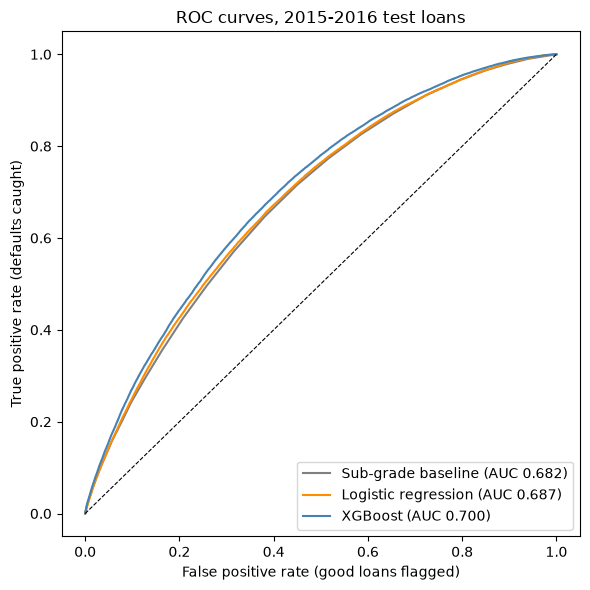

In [8]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, color in [("Sub-grade baseline", "gray"), ("Logistic regression", "darkorange"), ("XGBoost", "steelblue")]:
    fpr, tpr, _ = roc_curve(y_test, test_probs[name])
    auc = comparison.loc[comparison["model"] == name, "auc"].iloc[0]
    ax.plot(fpr, tpr, color=color, label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=0.8)
ax.set_title("ROC curves, 2015-2016 test loans")
ax.set_xlabel("False positive rate (good loans flagged)")
ax.set_ylabel("True positive rate (defaults caught)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMAGES / "roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: model comparison
XGBoost wins on every measure: AUC 0.700 vs. 0.682 for the sub-grade baseline, KS 0.29 vs. 0.27, and
the lowest Brier score. The gain over Lending Club's grade is real but modest. That is normal in consumer
credit: the sub-grade is already a strong score built from the same credit file. Logistic regression
barely beats the baseline (0.687).

Without any of Lending Club's pricing, XGBoost still reaches 0.687 from the borrower's own data, about
as good as the sub-grade itself. An AUC around 0.70 is typical for this dataset because defaults depend
heavily on life events (job loss, illness, divorce) that no application form captures.

### Calibration
For expected loss, the probabilities themselves have to be right, not just the ranking. Sort test loans
into ten equal groups by predicted PD and compare the average prediction with the actual default rate.

In [9]:
calibration = pd.DataFrame({"predicted": test_probs["XGBoost"], "actual": y_test.to_numpy()})
calibration["decile"] = pd.qcut(calibration["predicted"], 10, labels=range(1, 11))
calibration = calibration.groupby("decile", observed=True).agg(
    loans=("actual", "size"),
    avg_predicted_pd=("predicted", "mean"),
    actual_default_rate=("actual", "mean"),
).round(4)
calibration

,loans,avg_predicted_pd,actual_default_rate
decile,,,
1,37282,0.0269,0.0287
2,37281,0.0482,0.0565
3,37281,0.0672,0.0791
4,37281,0.0859,0.1006
5,37281,0.1051,0.1244
6,37281,0.1259,0.1492
7,37281,0.1499,0.1773
8,37281,0.1788,0.2121
9,37281,0.2170,0.2494


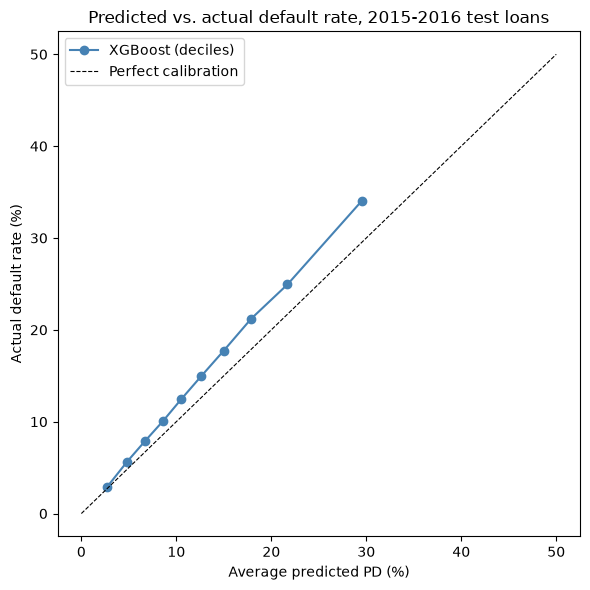

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(calibration["avg_predicted_pd"] * 100, calibration["actual_default_rate"] * 100, marker="o", color="steelblue",
        label="XGBoost (deciles)")
ax.plot([0, 50], [0, 50], color="black", linestyle="--", linewidth=0.8, label="Perfect calibration")
ax.set_title("Predicted vs. actual default rate, 2015-2016 test loans")
ax.set_xlabel("Average predicted PD (%)")
ax.set_ylabel("Actual default rate (%)")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: calibration
The model ranks risk well: every decile defaults more than the one before. But it **underestimates**
default across the board. It predicted 13.0% on average, and 15.2% actually defaulted.

This is not overfitting. It is drift: loans issued in 2015-2016 defaulted more than 2007-2014 loans with
the same profile. That matches the rising vintage curve in notebook 04, when Lending Club loosened
standards as it grew. A lender would catch this in monitoring and recalibrate, which notebook 06 does
before turning PDs into dollar losses.

C:\Users\furqa\Documents\lending-club-credit-risk\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


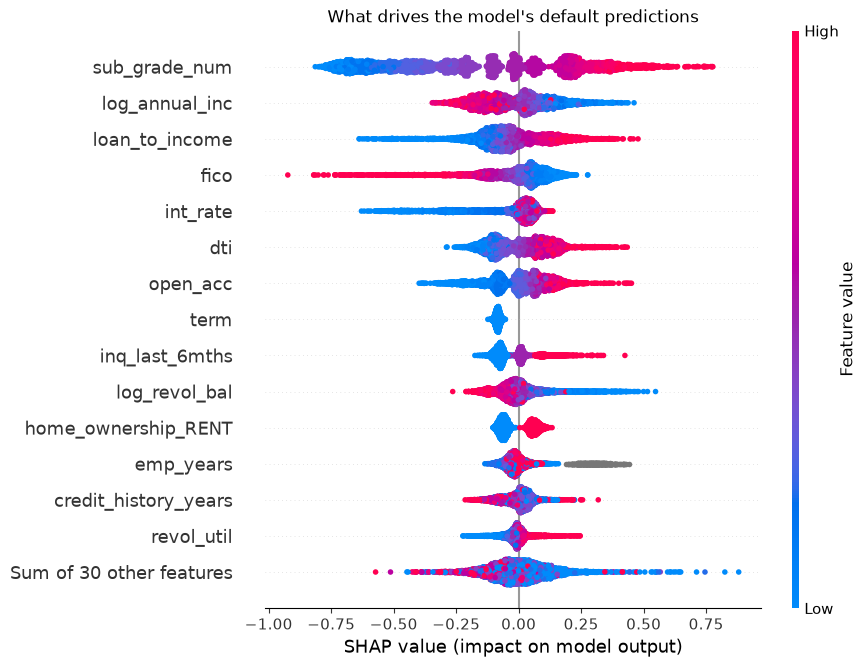

In [11]:
import shap

preprocess = xgb.named_steps["preprocess"]
feature_names = [name.split("__")[1] for name in preprocess.get_feature_names_out()]
sample = X_test.sample(5000, random_state=42)
sample_transformed = pd.DataFrame(preprocess.transform(sample), columns=feature_names)

explainer = shap.TreeExplainer(xgb.named_steps["model"])
shap_values = explainer(sample_transformed)

shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title("What drives the model's default predictions")
plt.savefig(IMAGES / "shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: drivers
Lending Club's sub-grade is the strongest single signal, followed by income, loan size relative to income,
and FICO score. Higher income and higher FICO lower the risk. A bigger loan relative to income, higher
debt-to-income, more open accounts, and more recent credit inquiries raise it. Renters are riskier than
homeowners, and borrowers who left employment length blank (gray points) are noticeably riskier. These
all match standard credit risk factors, which suggests the model learned real patterns.

### Loss severity
A PD alone is not a dollar figure. Expected loss = PD x exposure at default x loss given default.
Both are estimated from loans that defaulted in the **training years only**, so the 2015-2016 backtest
in the next notebook stays honest. They are estimated by term, because 60-month loans default with
more of the balance still owed.

In [12]:
defaults = loans[train & (loans["bad"] == 1)].copy()
defaults["ead"] = defaults["funded_amnt"] - defaults["total_rec_prncp"]
defaults["net_recovery"] = defaults["recoveries"] - defaults["collection_recovery_fee"]

severity = defaults.groupby("term").agg(
    defaults=("ead", "size"),
    funded=("funded_amnt", "sum"),
    ead=("ead", "sum"),
    net_recovery=("net_recovery", "sum"),
)
severity["ead_factor"] = severity["ead"] / severity["funded"]
severity["lgd"] = 1 - severity["net_recovery"] / severity["ead"]
severity["loss_per_dollar_funded"] = severity["ead_factor"] * severity["lgd"]
severity = severity[["defaults", "ead_factor", "lgd", "loss_per_dollar_funded"]].round(4)
severity

,defaults,ead_factor,lgd,loss_per_dollar_funded
term,,,,
36,44472,0.5768,0.8919,0.5144
60,17309,0.6963,0.8894,0.6193


In [13]:
grade_default_rates = y_train.groupby(loans.loc[train, "grade"]).mean().round(4)
grade_default_rates

grade
A    0.0558
B    0.1102
C    0.1759
D    0.2276
E    0.2855
F    0.3373
G    0.3697
Name: bad, dtype: float64

In [14]:
import joblib

MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

joblib.dump(
    {
        "model": xgb,
        "features": FEATURES,
        "severity": severity[["ead_factor", "lgd"]].to_dict(orient="index"),
        "grade_default_rates": grade_default_rates.to_dict(),
        "test_results": comparison.set_index("model").to_dict(orient="index"),
        "trained_on": "Loans issued 2007-2014 with a final outcome",
    },
    MODELS / "pd_model.joblib",
)
print(round((MODELS / "pd_model.joblib").stat().st_size / 1e6, 1), "MB saved")

1.2 MB saved


### Summary
- Tested **out of time** on 372,811 loans issued 2015-2016 that the model never saw.
- **XGBoost: AUC 0.700, Gini 0.40, KS 0.29**, beating Lending Club's sub-grade (0.682) and logistic
  regression (0.687).
- Borrower data alone, without Lending Club's pricing, reaches 0.687.
- The PDs rank risk well but run low for newer loans (13.0% predicted vs. 15.2% actual). Notebook 06
  recalibrates them.
- **Loss severity** from training-year defaults: a default costs 51% of the original amount on 36-month
  loans and 62% on 60-month loans.
- Saved to `models/pd_model.joblib` (1.2 MB) with the loss severity and grade benchmarks.